In [15]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ตั้งค่า Style สำหรับ Matplotlib & Seaborn ให้สวยงาม เป็นมืออาชีพ
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

PROCESSED_DIR = "../datasets/processed/"

print("Loading processed datasets...")
customers = pd.read_csv(os.path.join(PROCESSED_DIR, "dim_customers.csv"))
orders = pd.read_csv(os.path.join(PROCESSED_DIR, "fact_orders.csv"))
order_items = pd.read_csv(os.path.join(PROCESSED_DIR, "fact_order_items.csv"))
products = pd.read_csv(os.path.join(PROCESSED_DIR, "dim_products.csv"))
payments = pd.read_csv(os.path.join(PROCESSED_DIR, "fact_order_payments.csv"))
reviews = pd.read_csv(os.path.join(PROCESSED_DIR, "fact_order_reviews.csv"))

# Parse datetime columns
datetime_cols = ['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in datetime_cols:
    orders[col] = pd.to_datetime(orders[col])

print("✅ Data loaded successfully with Pure Pandas!")

Loading processed datasets...
✅ Data loaded successfully with Pure Pandas!


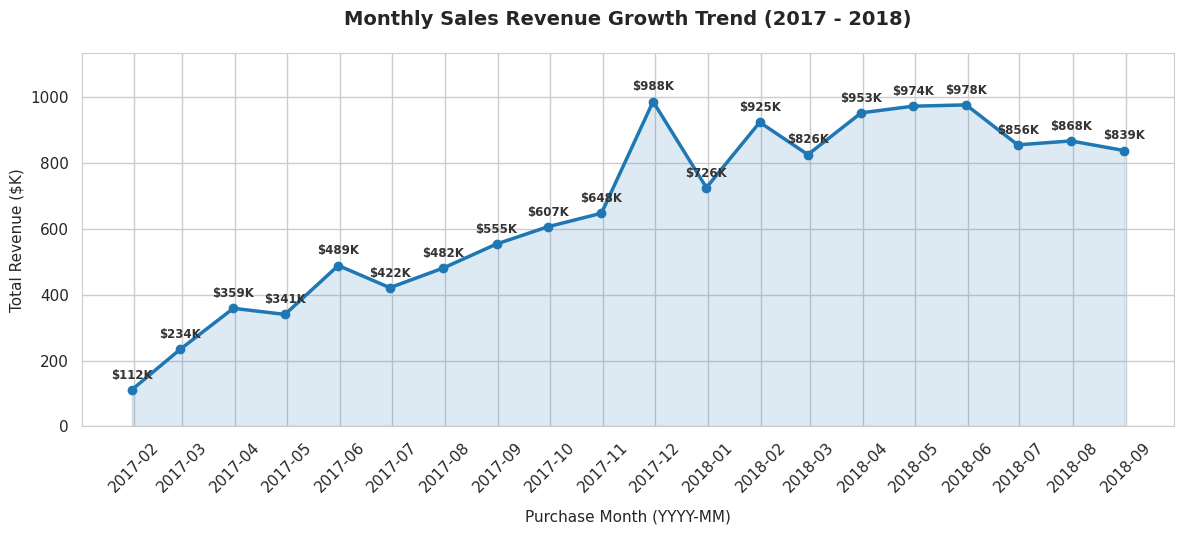

In [27]:
import matplotlib.dates as mdates

# 1. คำนวณยอดขายรายเดือน
orders_delivered = orders[orders['order_status'] == 'delivered'].merge(order_items, on='order_id')
monthly_sales = orders_delivered.set_index('order_purchase_timestamp').resample('M')['price'].sum().reset_index()

# 2. กรองช่วงปี 2017 - 2018 (ข้อมูลสมบูรณ์)
monthly_sales = monthly_sales[(monthly_sales['order_purchase_timestamp'] >= '2017-01-01') & 
                              (monthly_sales['order_purchase_timestamp'] <= '2018-08-31')]

# แปลงยอดขายเป็นหลักพัน ($K) เพื่อให้อ่านง่าย
monthly_sales['revenue_k'] = monthly_sales['price'] / 1000

# 3. วาดกราฟ
fig, ax = plt.subplots(figsize=(12, 5.5))

ax.plot(monthly_sales['order_purchase_timestamp'], monthly_sales['revenue_k'], 
        marker='o', color='#1f77b4', linewidth=2.5, markersize=6)
ax.fill_between(monthly_sales['order_purchase_timestamp'], monthly_sales['revenue_k'], 
                color='#1f77b4', alpha=0.15)

# 4. ใส่ Data Labels กำกับยอดขายตัวเลขจริงตรงทุกจุด Marker ($K)
for x, y in zip(monthly_sales['order_purchase_timestamp'], monthly_sales['revenue_k']):
    ax.annotate(f'${y:.0f}K',
                (x, y),
                textcoords="offset points",
                xytext=(0, 8),
                ha='center',
                fontsize=8.5,
                fontweight='bold',
                color='#333333')

# 5. จัดการแกน X ให้แสดงผลเป็น YYYY-MM ทุกเดือนอ่านง่าย
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=45)

# 6. ตั้งชื่อและระยะแกน Y
plt.title('Monthly Sales Revenue Growth Trend (2017 - 2018)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Purchase Month (YYYY-MM)', fontsize=11, labelpad=10)
plt.ylabel('Total Revenue ($K)', fontsize=11)
plt.ylim(0, monthly_sales['revenue_k'].max() * 1.15) # ขยายเพดานแกน Y เพื่อไม่ให้ตัวเลขติดขอบบน

plt.tight_layout()
plt.show()

--- Pareto 80/20 Insight ---
Total Categories: 72
Top Categories generating 80% of revenue: 17 categories



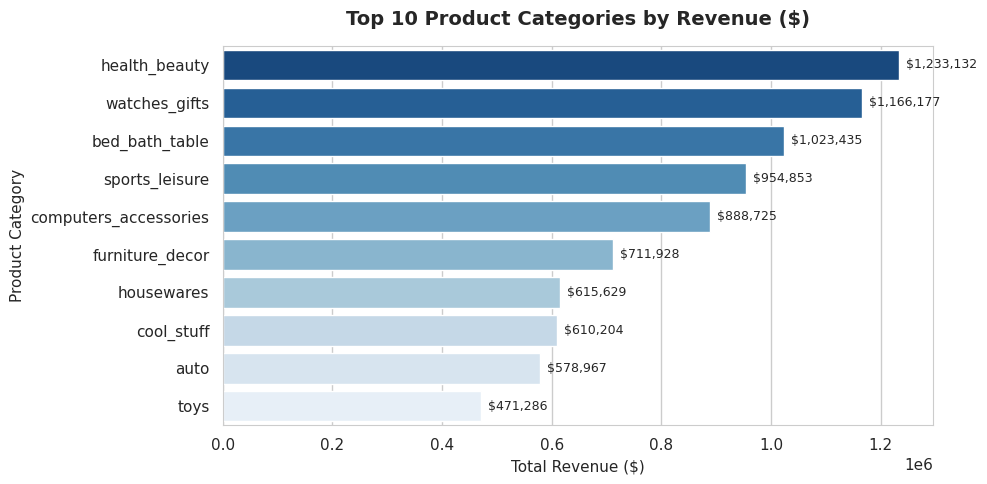

In [21]:
# Pareto 80/20 Analysis
df_prod_sales = order_items.merge(products, on='product_id').merge(orders, on='order_id')
df_prod_sales = df_prod_sales[df_prod_sales['order_status'] == 'delivered']

pareto = df_prod_sales.groupby('product_category_name_english')['price'].sum().reset_index()
pareto = pareto.sort_values(by='price', ascending=False).reset_index(drop=True)
pareto['cumulative_revenue'] = pareto['price'].cumsum()
pareto['cumulative_percent'] = (pareto['cumulative_revenue'] / pareto['price'].sum()) * 100

top_80 = pareto[pareto['cumulative_percent'] <= 80]
print(f"--- Pareto 80/20 Insight ---")
print(f"Total Categories: {len(pareto)}")
print(f"Top Categories generating 80% of revenue: {len(top_80)} categories\n")

# Plot Top 10 Categories
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=pareto.head(10), x='price', y='product_category_name_english', palette='Blues_r', hue='product_category_name_english')

plt.title('Top 10 Product Categories by Revenue ($)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Total Revenue ($)', fontsize=11)
plt.ylabel('Product Category', fontsize=11)

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'${width:,.0f}', (width, p.get_y() + p.get_height() / 2.),
                ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()

Overall Late Delivery Rate: 7.99%



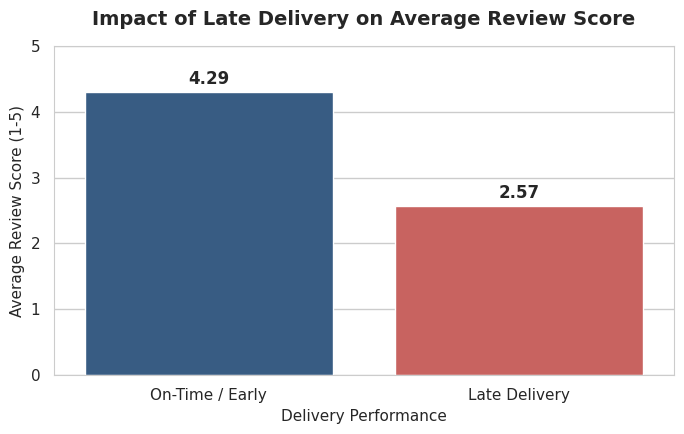

In [24]:
# คำนวณผลกระทบของการส่งช้าต่อ Review Score
df_delivery = orders[orders['order_status'] == 'delivered'].merge(reviews, on='order_id').dropna(subset=['order_delivered_customer_date'])
df_delivery['days_before_estimate'] = (df_delivery['order_estimated_delivery_date'] - df_delivery['order_delivered_customer_date']).dt.days
df_delivery['is_late'] = df_delivery['days_before_estimate'] < 0

score_summary = df_delivery.groupby('is_late').agg(
    order_count=('order_id', 'nunique'),
    avg_review_score=('review_score', 'mean')
).reset_index()

score_summary['status_label'] = score_summary['is_late'].map({False: 'On-Time / Early', True: 'Late Delivery'})

print(f"Overall Late Delivery Rate: {(df_delivery['is_late'].mean() * 100):.2f}%\n")
# Plot Review Score Comparison (แก้ไข Warning palette & Font เต้าหู้)
plt.figure(figsize=(7, 4.5))
ax = sns.barplot(
    data=score_summary, 
    x='status_label', 
    y='avg_review_score', 
    hue='status_label',
    palette=['#2b5c8f', '#d9534f'],
    legend=False
)

plt.title('Impact of Late Delivery on Average Review Score', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Delivery Performance', fontsize=11)
plt.ylabel('Average Review Score (1-5)', fontsize=11)
plt.ylim(0, 5)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', xytext=(0, 3), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()

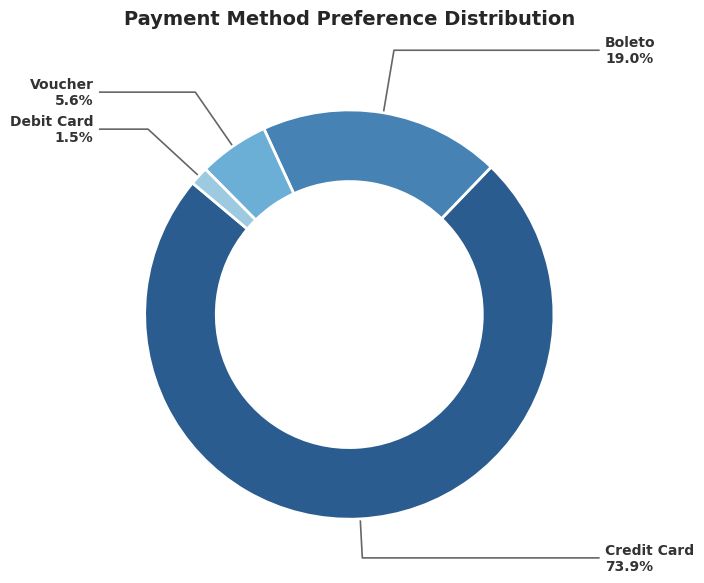

In [26]:
import numpy as np

# 1. เตรียมข้อมูลและจัดรูปแบบชื่อ
payment_counts = payments['payment_type'].value_counts()
payment_counts = payment_counts[payment_counts.index != 'not_defined']

labels = [label.replace('_', ' ').title() for label in payment_counts.index]
values = payment_counts.values
total = values.sum()
percentages = [v / total * 100 for v in values]

# 2. ตั้งค่า Figure
fig, ax = plt.subplots(figsize=(9, 6), subplot_kw=dict(aspect="equal"))
colors = ['#2b5c8f', '#4682b4', '#6baed6', '#9ecae1']

# 3. วาด Donut Chart
wedges, texts = ax.pie(
    values, 
    startangle=140, 
    colors=colors,
    wedgeprops=dict(width=0.35, edgecolor='w', linewidth=2)
)

# 4. วาดเส้นชี้และใส่ Label + Percentage ชี้ออกมาข้างนอก
bbox_props = dict(boxstyle="square,pad=0.3", fc="w", ec="none", lw=0.7)
kw = dict(arrowprops=dict(arrowstyle="-", color="#666666", lw=1.2), zorder=0)

for i, p in enumerate(wedges):
    ang = (p.theta2 - p.theta1) / 2. + p.theta1
    y = np.sin(np.deg2rad(ang))
    x = np.cos(np.deg2rad(ang))
    
    # กำหนดทิศทางของเส้นชี้ (ซ้าย/ขวา)
    horizontalalignment = {-1: "right", 1: "left"}[int(np.sign(x))]
    connectionstyle = f"angle,angleA=0,angleB={ang}"
    kw["arrowprops"]["connectionstyle"] = connectionstyle
    
    # ข้อความแสดงผล (ชื่อ + %)
    label_text = f"{labels[i]}\n{percentages[i]:.1f}%"
    
    # ชี้เส้นออกมาด้านนอก
    ax.annotate(
        label_text, 
        xy=(x * 0.85, y * 0.85), 
        xytext=(1.25 * np.sign(x), 1.25 * y),
        horizontalalignment=horizontalalignment,
        fontsize=10,
        fontweight='bold',
        color='#333333',
        **kw
    )

plt.title('Payment Method Preference Distribution', fontsize=14, fontweight='bold', pad=25)
plt.tight_layout()
plt.show()